# 03.2 - Signal and noise on one scale

The map in `03.1` tells you a *ratio*. This notebook puts the excitation and the shot
noise into the **same units**, so the question "is it measurable at this dose" has an
absolute answer you can read off an axis.

The whole notebook is one equation:

$$\hat{I} \;=\; \mathrm{ref} \;+\; n
\qquad\Longrightarrow\qquad
\frac{\langle \mathrm{ref},\hat{I}\rangle}{\lVert \mathrm{ref}\rVert}
\;=\; \underbrace{\lVert \mathrm{ref}\rVert}_{\text{signal}} \;+\;
\underbrace{\frac{\langle \mathrm{ref},n\rangle}{\lVert \mathrm{ref}\rVert}}_{\text{noise, std }\sigma_{MF}}$$

Measurable means $\lVert \mathrm{ref}\rVert \gtrsim \sigma_{MF}$. Both sides are computed
below, from first principles, and both are checked against the simulated data.

## The chain, which is the part worth following

It is four hops from a picture of the object to a number comparable with shot noise, and
each one changes what the quantity *is*:

| | object | lives on | what it is |
|---|---|---|---|
| 1 | $\Delta\varphi(\mathbf{r})$ | real space, rad | the thing we want: a 2D phase image |
| 2 | $\Delta\tilde\varphi(\mathbf{q})$ | object frequency | its spectrum - where its energy sits |
| 3 | $\hat{I}(\mathbf{Q},\mathbf{k})$ | scan freq x detector | what the microscope records, after one FT over scan |
| 4 | $\lVert \mathrm{ref}\rVert(\mathbf{q})$ | object frequency | the detector axis collapsed away: one number per frequency |

Hop 3 is where the instrument enters, through $\Gamma$. Hop 4 is where the matched filter
turns a detector plane into a scalar. The claim this notebook checks is that all four
compose into one closed-form prediction:

$$\boxed{\;\lVert \mathrm{ref}\rVert(\mathbf{q})\;=\;\tfrac12\,
\bigl|\Delta\tilde\varphi(\mathbf{q})\bigr|\;
\frac{\lVert\Gamma(\cdot,\mathbf{q})\rVert}{N_{\rm BF}}\;}$$

with $N_{\rm BF}=\sum_{\mathbf{k}}|A(\mathbf{k})|^2$ the pattern normalisation, the
$\tfrac12$ from $\Delta I=\tfrac12(I_{\rm on}-I_{\rm off})$, and $\Gamma$ the
instrument-only kernel from `03.4`. Nothing in it is fitted.


In [1]:
%load_ext autoreload
%autoreload 2

import json, sys, time, gc
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import map_coordinates

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
RESULTS_DIR = NOTEBOOK_DIR / "results"; RESULTS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(NOTEBOOK_DIR.parent))
import method_wrappers as mw
from quantem.core import config
config.set_device(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

OVERRIDES = {"defocus_C10_ang": 0.0, "convergence_semiangle_mrad": 30.0, "step_ang": 0.1}
PREFIX = "focus0_s010"
with open(DATA_DIR / "ideal_geometry.json") as h:
    BASE_META = json.load(h)
BASE_PATH, EXC_PATH, META = mw.ensure_dataset(DATA_DIR, BASE_META, OVERRIDES, prefix=PREFIX)

LAM   = META["beam"]["wavelength_ang"]
ALPHA = META["beam"]["convergence_semiangle_mrad"]
step  = META["scan"]["step_ang"]
n     = META["scan"]["n_positions_per_side"]
n_det = META["detector"]["n_pixels_binned"]
pitch = META["detector"]["binned_pitch_mrad"]
odx   = META["cell"]["dx_ang"]
nobj  = META["cell"]["n_pixels"]
N_POS = n * n
BW    = META["probe"]["bandwidth_inv_ang"]

src_off = np.load(BASE_PATH, mmap_mode="r")
src_on  = np.load(EXC_PATH, mmap_mode="r")

dQ = 1.0 / (n * step)
f_car = (np.arange(n) - n / 2) * dQ          # carrier channel: q = 0 at the array centre
QX, QY = np.meshgrid(f_car, f_car, indexing="ij")
Rc = np.hypot(QX, QY)
q_det = (np.arange(n_det) - n_det / 2 + 0.5) * pitch
KXn, KYn = np.meshgrid(q_det, q_det, indexing="ij")

print(f"{n}^2 scan at {step} A,  dQ = {dQ:.4f} 1/A,  bandwidth {BW:.3f} 1/A")
print(f"detector {n_det}^2 at {pitch:.5f} mrad/px")


cuda:0
  cached: focus0_s010_base_noiseless.npy, focus0_s010_excited_noiseless.npy  (C10 0.0 A, 30.0 mrad, 300^2 at 0.1 A)
300^2 scan at 0.1 A,  dQ = 0.0333 1/A,  bandwidth 1.233 1/A
detector 192^2 at 0.54657 mrad/px


## Hop 1 and 2 - the object and its spectrum

$\Delta\varphi$ is resampled onto the **scan** grid, because that is the grid the partial
Fourier transform is taken on; using the finer object grid would put the spectrum on a
different frequency axis and nothing downstream would line up.

The transform is the plain unnormalised `np.fft.fft2`, matching the convention used for
the measurement everywhere in this block. Its index $i$ means frequency
`fftfreq[i]`, whereas the carrier channel's index $i$ means $(i-N/2)\,\Delta q$ - so one
`fftshift` converts between them. That shift is bookkeeping, not physics.


delta phi on the scan grid: (300, 300), peak 0.02087 rad
cumulative energy of delta phi below |q|: 0.05: 17.2%, 0.1: 62.8%, 0.15: 94.8%, 0.2: 96.5%, 0.3: 98.6%, 0.5: 99.9%


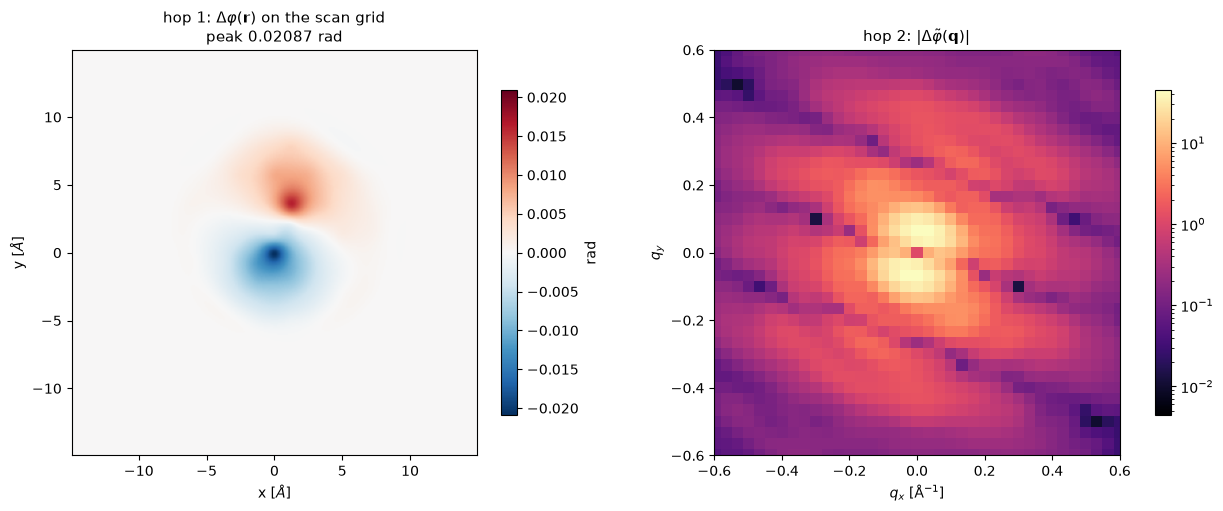

In [2]:
dphi = np.load(DATA_DIR / "ideal_truth.npz")["delta_phi_true"].astype(np.float64)
obj_ax = (np.arange(nobj) - nobj // 2) * odx
scan_ax = (np.arange(n) - (n - 1) / 2) * step
_co = (scan_ax - obj_ax[0]) / odx
_gy, _gx = np.meshgrid(_co, _co, indexing="ij")
dphi_s = map_coordinates(dphi, np.vstack([_gy.ravel(), _gx.ravel()]),
                         order=1, mode="nearest").reshape(n, n)
DPHI = np.fft.fft2(dphi_s)                       # unnormalised, matches the partial FT
DPHI_car = np.fft.fftshift(DPHI)                 # onto the carrier-channel index

print(f"delta phi on the scan grid: {dphi_s.shape}, peak {np.abs(dphi_s).max():.5f} rad")
cum = [( r, (np.abs(DPHI_car)[Rc < r] ** 2).sum() / (np.abs(DPHI_car) ** 2).sum())
       for r in (0.05, 0.10, 0.15, 0.20, 0.30, 0.50)]
print("cumulative energy of delta phi below |q|: " +
      ", ".join(f"{r}: {100*c:.1f}%" for r, c in cum))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.0), constrained_layout=True)
lim = np.abs(dphi_s).max()
im = ax[0].imshow(dphi_s.T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
                  extent=[scan_ax[0], scan_ax[-1]] * 2)
ax[0].set_title(r"hop 1: $\Delta\varphi(\mathbf{r})$ on the scan grid" +
                f"\npeak {lim:.5f} rad", fontsize=11)
ax[0].set_xlabel(r"x [$\AA$]"); ax[0].set_ylabel(r"y [$\AA$]")
fig.colorbar(im, ax=ax[0], shrink=.8, label="rad")

m = np.abs(DPHI_car)
im = ax[1].imshow(m.T, origin="lower", cmap="magma", norm=LogNorm(vmin=m.max()*1e-4,
                  vmax=m.max()), extent=[f_car[0], f_car[-1]] * 2)
ax[1].set_xlim(-0.6, 0.6); ax[1].set_ylim(-0.6, 0.6)
ax[1].set_title(r"hop 2: $|\Delta\tilde\varphi(\mathbf{q})|$", fontsize=11)
ax[1].set_xlabel(r"$q_x$ [$\mathrm{\AA^{-1}}$]"); ax[1].set_ylabel(r"$q_y$")
fig.colorbar(im, ax=ax[1], shrink=.8)
plt.show()


## Hop 3 - the instrument: $\Gamma$, and what it does to each frequency

For a weak phase object the partial Fourier transform of the recorded intensity is, to
first order,

$$\hat{I}(\mathbf{Q},\mathbf{k})=i\,\tilde\varphi(\mathbf{Q})\;\Gamma(\mathbf{k},\mathbf{Q}),
\qquad
\Gamma=\tilde{A}^{*}(\mathbf{k})\tilde{A}(\mathbf{k}-\mathbf{Q})-\tilde{A}(\mathbf{k})\tilde{A}^{*}(\mathbf{k}+\mathbf{Q})$$

One unknown scalar per frequency, multiplied by a known kernel that is spread over the
detector. **$\Gamma$ contains nothing from the sample** - only the aperture, the
aberrations and $\mathbf{q}$.

The interlacing puts the differential signal on the carrier: at
$\mathbf{Q}=\mathbf{Q}_{c}+\mathbf{q}$ the measurement is $\mathcal F[\Delta I](\mathbf{q})$
with $\Delta I=\tfrac12(I_{\rm on}-I_{\rm off})$, so the *object* frequency there is
$\mathbf{q}$, not $\mathbf{Q}$.

$\lVert\Gamma(\cdot,\mathbf{q})\rVert$ is the single number that says how much of that
frequency the microscope transfers. It vanishes at $\mathbf{q}=0$ (the three discs
coincide, the two terms cancel) and again past $|\mathbf{q}| = 2k_{\rm cut}$ (the discs
stop overlapping).


N_BF = sum_k |A|^2 = 9,408   (||Gamma|| in 0 s)
||Gamma|| is non-zero on 4.9% of the map (= the fraction inside the bandwidth)


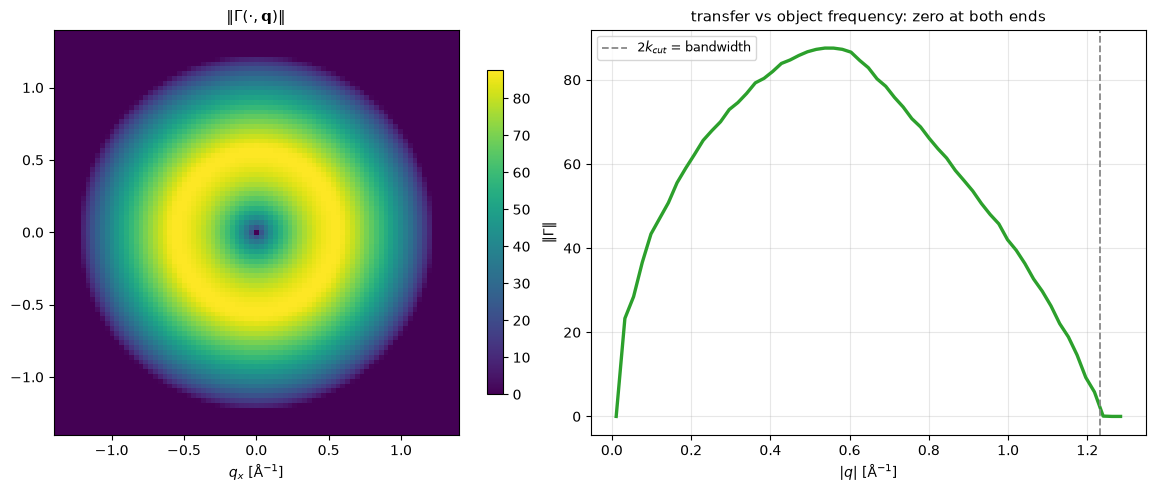

In [3]:
k_cut = ALPHA                    # mrad; the aperture radius

def A_ap(kx, ky):
    """Soft-edged aperture, one pixel of linear taper."""
    return torch.clip((k_cut - torch.sqrt(kx * kx + ky * ky)) / pitch + 0.5, 0.0, 1.0)

_KX = torch.as_tensor(KXn, dtype=torch.float32, device=DEVICE)
_KY = torch.as_tensor(KYn, dtype=torch.float32, device=DEVICE)
_Ak = A_ap(_KX, _KY)
N_BF = float(_Ak.square().sum())          # the pattern normalisation, sum_k |A|^2

t0 = time.time()
GAMMA_NORM = np.zeros((n, n))
_sx = torch.as_tensor(QX * LAM * 1e3, dtype=torch.float32, device=DEVICE)
_sy = torch.as_tensor(QY * LAM * 1e3, dtype=torch.float32, device=DEVICE)
for i in range(n):
    sx = _sx[i].view(-1, 1, 1); sy = _sy[i].view(-1, 1, 1)
    g = _Ak.unsqueeze(0) * (A_ap(_KX.unsqueeze(0) - sx, _KY.unsqueeze(0) - sy)
                            - A_ap(_KX.unsqueeze(0) + sx, _KY.unsqueeze(0) + sy))
    GAMMA_NORM[i] = g.square().sum(dim=(-2, -1)).sqrt().cpu().numpy()
    del g
torch.cuda.empty_cache()
print(f"N_BF = sum_k |A|^2 = {N_BF:,.0f}   (||Gamma|| in {time.time()-t0:.0f} s)")
print(f"||Gamma|| is non-zero on {100*(GAMMA_NORM>0).mean():.1f}% of the map "
      f"(= the fraction inside the bandwidth)")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
im = ax[0].imshow(GAMMA_NORM.T, origin="lower", cmap="viridis",
                  extent=[f_car[0], f_car[-1]] * 2)
ax[0].set_xlim(-1.4, 1.4); ax[0].set_ylim(-1.4, 1.4)
ax[0].set_title(r"$\|\Gamma(\cdot,\mathbf{q})\|$", fontsize=11)
ax[0].set_xlabel(r"$q_x$ [$\mathrm{\AA^{-1}}$]"); fig.colorbar(im, ax=ax[0], shrink=.8)

rr = np.linspace(0, BW * 1.05, 60)
prof = [np.median(GAMMA_NORM[(Rc >= a) & (Rc < b)]) if ((Rc >= a) & (Rc < b)).any()
        else np.nan for a, b in zip(rr[:-1], rr[1:])]
ax[1].plot(0.5 * (rr[:-1] + rr[1:]), prof, lw=2.4, color="#2ca02c")
ax[1].axvline(BW, color="#888", ls="--", lw=1.3, label=r"$2k_{cut}$ = bandwidth")
ax[1].set_xlabel(r"$|q|$ [$\mathrm{\AA^{-1}}$]"); ax[1].set_ylabel(r"$\|\Gamma\|$")
ax[1].set_title("transfer vs object frequency: zero at both ends", fontsize=11)
ax[1].grid(alpha=.3); ax[1].legend(fontsize=9)
plt.show()


## Hop 4 - collapsing the detector: the prediction, and the check

The matched filter turns each detector plane into one number. With
$\mathrm{ref}=i\,\tfrac12\Delta\tilde\varphi\,\Gamma/N_{\rm BF}$,

$$\lVert \mathrm{ref}\rVert(\mathbf{q})=\tfrac12\,|\Delta\tilde\varphi(\mathbf{q})|\,
\lVert\Gamma(\cdot,\mathbf{q})\rVert \,/\, N_{\rm BF}$$

The $1/N_{\rm BF}$ is there because the stored diffraction patterns are normalised to sum
1, while $\Gamma$ is built from an aperture of unit amplitude - so the data is the model
divided by $\sum_k|A|^2$.

**Nothing here is fitted.** The cell below computes the left side from the simulated
interlaced cube and the right side from the truth image plus the aperture, and compares
them. If the ratio is flat and equal to 1, the chain is right.


In [4]:
PRED = 0.5 * np.abs(DPHI_car) * GAMMA_NORM / N_BF

t0 = time.time()
cube0 = mw.build_dosed_cube(src_off, src_on, None, step, rows=16)   # noiseless, = ref
pbar = cube0.mean(axis=(0, 1))
den = torch.zeros((n, n), device=DEVICE)
wvar = torch.zeros((n, n), device=DEVICE)
_pb = torch.as_tensor(pbar, device=DEVICE)
for k0 in range(0, n_det, 16):
    k1 = min(k0 + 16, n_det)
    G = torch.fft.fft2(torch.as_tensor(np.ascontiguousarray(cube0[:, :, k0:k1, :]),
                                       device=DEVICE).to(torch.complex64), dim=(0, 1))
    a2 = G.abs().square(); del G
    den += a2.sum(dim=(-2, -1))
    wvar += (a2 * _pb[k0:k1, :]).sum(dim=(-2, -1))      # for the noise, next section
    del a2
REF_NORM = np.sqrt(den.cpu().numpy())
PBAR_EFF = (wvar / den.clamp(min=1e-30)).cpu().numpy()
torch.cuda.empty_cache()
print(f"measured ||ref|| from the simulated cube ({time.time()-t0:.0f} s)")

sel = (Rc > 0.02) & (Rc < 0.30) & (GAMMA_NORM > 0)
ratio = REF_NORM[sel] / np.maximum(PRED[sel], 1e-30)
print(f"\nmeasured / predicted over {int(sel.sum())} bins, 0.02 < |q| < 0.30:")
print(f"   median {np.median(ratio):.4f}   sd/mean {ratio.std()/ratio.mean()*100:.1f}%")
print(f"\n{'|q| band':>14s} {'measured':>12s} {'predicted':>12s} {'ratio':>8s}")
print("-" * 50)
for lo, hi in ((0.03, 0.06), (0.06, 0.10), (0.10, 0.15), (0.15, 0.22), (0.22, 0.30)):
    b = (Rc >= lo) & (Rc < hi) & (GAMMA_NORM > 0)
    print(f"  {lo:.2f}-{hi:.2f}    {np.median(REF_NORM[b]):12.4e} "
          f"{np.median(PRED[b]):12.4e} {np.median(REF_NORM[b]/np.maximum(PRED[b],1e-30)):8.4f}")
print("-" * 50)
print("A flat ratio at 1 closes the chain: phase image -> spectrum -> diffraction\n"
      "patterns -> one number per frequency, with no free parameter. The residual\n"
      "drift at the smallest |q| is the soft aperture edge, which matters more as the\n"
      "overlap lunes thin.")


measured ||ref|| from the simulated cube (10 s)

measured / predicted over 248 bins, 0.02 < |q| < 0.30:
   median 0.9985   sd/mean 9.6%

      |q| band     measured    predicted    ratio
--------------------------------------------------
  0.03-0.06      3.6259e-02   3.7984e-02   0.9633
  0.06-0.10      6.5307e-02   6.6898e-02   0.9792
  0.10-0.15      2.9976e-02   3.0209e-02   0.9937
  0.15-0.22      9.7919e-03   9.7585e-03   1.0033
  0.22-0.30      6.2072e-03   6.2135e-03   1.0016
--------------------------------------------------
A flat ratio at 1 closes the chain: phase image -> spectrum -> diffraction
patterns -> one number per frequency, with no free parameter. The residual
drift at the smallest |q| is the soft aperture edge, which matters more as the
overlap lunes thin.


## The other side: what shot noise becomes, in the same units

The step that is easy to get wrong is the Fourier transform, so it is worth doing slowly.

**1. At one scan position.** Each pattern is normalised to sum 1 and then Poisson-sampled
at $N = D\,\Delta^{2}$ electrons, so $\hat{I}_j(\mathbf{k})=n_j(\mathbf{k})/N$ with
$n\sim\mathrm{Poisson}(N p_j)$, and

$$\mathrm{Var}\bigl[\hat{I}_j(\mathbf{k})\bigr]=\frac{p_j(\mathbf{k})}{N}$$

**2. Through the partial FT.** $G(\mathbf{Q},\mathbf{k})=\sum_j \hat{I}_j(\mathbf{k})\,
e^{-2\pi i\mathbf{Q}\cdot\mathbf{r}_j}$ is a sum of **independent** terms multiplied by
phases of **unit modulus**. Phases cannot change a variance, so the variances simply add:

$$\mathbb E\bigl|\delta G(\mathbf{Q},\mathbf{k})\bigr|^{2}
=\sum_j \mathrm{Var}[\hat{I}_j]=\frac{N_{\rm pos}\,\bar{p}(\mathbf{k})}{N}$$

and this is **independent of $\mathbf{Q}$**. Shot noise is white in scan frequency: the
floor at the carrier is the same as the floor anywhere else. That is the fact that makes
the whole comparison simple, and it is the answer to "where does the shot noise go when
you transform".

**3. Through the filter.** The noise term is $\langle \mathrm{ref},n\rangle/\lVert \mathrm{ref}\rVert$,
whose mean square is the $|\mathrm{ref}|^{2}$-weighted average of the per-pixel variance:

$$\boxed{\;\sigma_{MF}^{2}(\mathbf{q})=\frac{N_{\rm pos}}{D\,\Delta^{2}}\cdot
\frac{\sum_{\mathbf{k}}|\mathrm{ref}|^{2}\,\bar{p}(\mathbf{k})}
{\sum_{\mathbf{k}}|\mathrm{ref}|^{2}}\;}$$

so $\sigma_{MF}\propto 1/\sqrt{D}$ while $\lVert \mathrm{ref}\rVert$ does not depend on
dose at all - the patterns are normalised. Hence $\mathrm{SNR}\propto\sqrt{D}$ exactly.

**4. One subtlety.** We take the **modulus** of a complex quantity. The modulus of
circular complex Gaussian noise is Rayleigh, so the floor sits at
$\mathbb E|z| = \tfrac{\sqrt\pi}{2}\sigma_{MF}=0.886\,\sigma_{MF}$, **not at zero**, and
its median is $\sqrt{2\ln 2}/\sqrt2 = 0.833\,\sigma_{MF}$. A matched-filter map can
therefore never read zero, which is why a *ratio* to its own floor was always a slightly
awkward statistic and an absolute scale is better.


In [5]:
RAYLEIGH_MEAN = np.sqrt(np.pi) / 2        # E|z| / rms
RAYLEIGH_MEDIAN = np.sqrt(2 * np.log(2)) / np.sqrt(2)

def sigma_mf(dose):
    """Predicted rms of the matched-filter noise, in the same units as ||ref||."""
    return np.sqrt(PBAR_EFF * N_POS / (dose * step ** 2))


def matched_map(cube, ref_cube, slab=16):
    num = torch.zeros((n, n), dtype=torch.complex64, device=DEVICE)
    dn = torch.zeros((n, n), device=DEVICE)
    for k0 in range(0, n_det, slab):
        k1 = min(k0 + slab, n_det)
        g = torch.fft.fft2(torch.as_tensor(np.ascontiguousarray(cube[:, :, k0:k1, :]),
                                           device=DEVICE).to(torch.complex64), dim=(0, 1))
        r = torch.fft.fft2(torch.as_tensor(np.ascontiguousarray(ref_cube[:, :, k0:k1, :]),
                                           device=DEVICE).to(torch.complex64), dim=(0, 1))
        num += (r.conj() * g).sum(dim=(-2, -1))
        dn += r.abs().square().sum(dim=(-2, -1))
        del g, r
    torch.cuda.empty_cache()
    return (num.abs() / dn.clamp(min=1e-30).sqrt()).cpu().numpy()


BUF = np.empty(src_off.shape, dtype=np.float32)
print(f"{'dose':>8s} {'predicted median':>17s} {'measured median':>16s} {'ratio':>7s}")
print("-" * 54)
rows = []
for dose in (1e7, 1e6, 1e5):
    noisy = mw.build_dosed_cube(src_off, src_on, dose, step, out=BUF, rows=16, seed=3)
    mp = matched_map(noisy, cube0)
    sig = sigma_mf(dose)
    quiet = (REF_NORM / np.maximum(sig, 1e-30) < 0.3) & (Rc <= BW) & (GAMMA_NORM > 0)
    pr = float(np.median(RAYLEIGH_MEDIAN * sig[quiet]))
    me = float(np.median(mp[quiet]))
    rows.append(dict(dose=dose, predicted=pr, measured=me, ratio=me / pr,
                     n_bins=int(quiet.sum())))
    print(f"{dose:8.0e} {pr:17.5f} {me:16.5f} {me/pr:7.3f}")
    del noisy, mp; gc.collect(); torch.cuda.empty_cache()
print("-" * 54)
print("Predicted with the Rayleigh MEDIAN constant 0.833, because the measurement is a\n"
      "median over noise-dominated bins. Agreement here means the Poisson -> FT ->\n"
      "filter chain is right, including the factor that is easiest to drop.")
del cube0; gc.collect()


    dose  predicted median  measured median   ratio
------------------------------------------------------


   1e+07           0.00800          0.00779   0.974


   1e+06           0.02536          0.02386   0.941


   1e+05           0.08023          0.07779   0.970
------------------------------------------------------
Predicted with the Rayleigh MEDIAN constant 0.833, because the measurement is a
median over noise-dominated bins. Agreement here means the Poisson -> FT ->
filter chain is right, including the factor that is easiest to drop.


0

## Both on one axis

Signal does not move with dose; the floor falls as $1/\sqrt{D}$. Where they cross is the
highest object frequency of the excitation that is above shot noise - everything finer
than that is buried, which is why a band-limited reconstruction is not throwing anything
away.


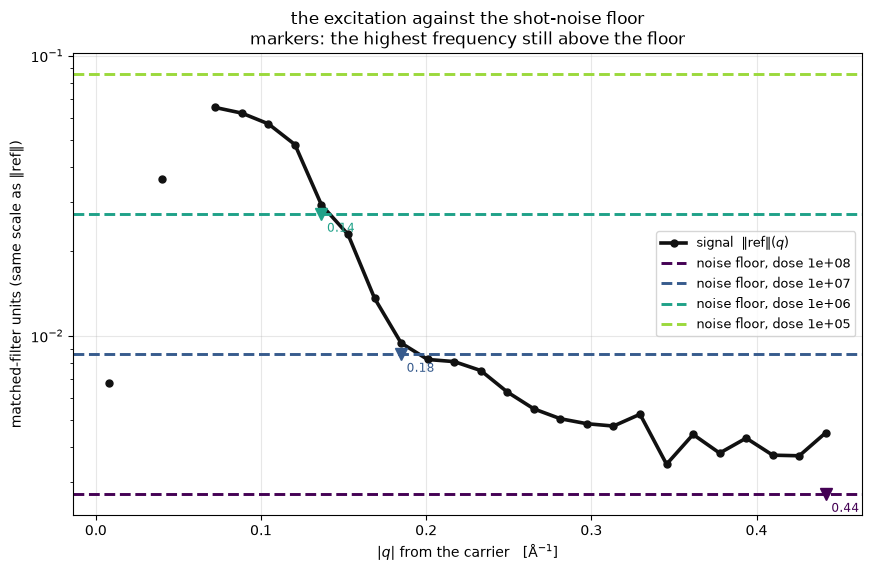

    band [1/A]     ||ref||  SNR @1e6   dose for SNR=3
-------------------------------------------------------
  0.03-0.08     4.7002e-02      1.55         3.75e+06
  0.08-0.15     3.1269e-02      1.02         8.64e+06
  0.15-0.30     7.3723e-03      0.24         1.57e+08
-------------------------------------------------------

wrote 032_signal_vs_noise.json


In [6]:
DOSES_SHOW = [1e8, 1e7, 1e6, 1e5]
ring = (Rc > 0) & (Rc <= 0.45)
edges = np.linspace(0, 0.45, 29)
ctr = 0.5 * (edges[:-1] + edges[1:])
sig_prof = np.array([np.median(REF_NORM[(Rc >= a) & (Rc < b)])
                     if ((Rc >= a) & (Rc < b)).any() else np.nan
                     for a, b in zip(edges[:-1], edges[1:])])

fig, ax = plt.subplots(figsize=(8.6, 5.6), constrained_layout=True)
ax.plot(ctr, sig_prof, "o-", lw=2.6, color="#111", ms=5,
        label=r"signal  $\|\mathrm{ref}\|(q)$")
for dose, col in zip(DOSES_SHOW, plt.cm.viridis(np.linspace(0, 0.85, len(DOSES_SHOW)))):
    fl = RAYLEIGH_MEAN * np.median(sigma_mf(dose)[ring])
    ax.axhline(fl, color=col, lw=2.1, ls="--",
               label=f"noise floor, dose {dose:.0e}")
    cross = ctr[np.isfinite(sig_prof) & (sig_prof > fl)]
    if cross.size:
        ax.plot(cross.max(), fl, "v", color=col, ms=9)
        ax.annotate(f"{cross.max():.2f}", (cross.max(), fl), textcoords="offset points",
                    xytext=(4, -13), fontsize=8.5, color=col)
ax.set_yscale("log")
ax.set_xlabel(r"$|q|$ from the carrier   [$\mathrm{\AA^{-1}}$]")
ax.set_ylabel(r"matched-filter units (same scale as $\|\mathrm{ref}\|$)")
ax.set_title("the excitation against the shot-noise floor\n"
             "markers: the highest frequency still above the floor", fontsize=12)
ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.show()

print(f"{'band [1/A]':>14s} {'||ref||':>11s} {'SNR @1e6':>9s} {'dose for SNR=3':>16s}")
print("-" * 55)
out = []
for lo, hi in ((0.03, 0.08), (0.08, 0.15), (0.15, 0.30)):
    b = (Rc >= lo) & (Rc < hi) & (GAMMA_NORM > 0)
    s = float(np.median(REF_NORM[b]))
    snr6 = s / float(np.median(sigma_mf(1e6)[b]))
    d3 = 1e6 * (3.0 / snr6) ** 2
    out.append(dict(lo=lo, hi=hi, ref=s, snr_1e6=snr6, dose_snr3=d3))
    print(f"  {lo:.2f}-{hi:.2f}    {s:11.4e} {snr6:9.2f} {d3:16.2e}")
print("-" * 55)

with open(RESULTS_DIR / "032_signal_vs_noise.json", "w") as h:
    json.dump(dict(prefix=PREFIX, N_BF=N_BF, n_pos=N_POS, step_ang=step,
                   noise_check=rows, bands=out), h, indent=2)
print("\nwrote 032_signal_vs_noise.json")


## What this gives you

* **An absolute threshold.** At $10^6$ the excitation sits above the shot-noise floor only
  out to $|q|\approx 0.14\ \mathrm{\AA^{-1}}$. That is a measurement, not a tuning choice,
  and it is where the band limit $Q_{\max}=0.15$ used in `03` comes from - the cut is
  placed where the data stops carrying anything.
* **Per-frequency SNR is only about 1 at $10^6$**, yet the reconstruction reaches
  $\rho\approx0.81$. No contradiction: the excitation occupies roughly 68 frequency bins
  inside the ring, and combining them gains $\sqrt{68}\approx8$, which puts the
  whole-image figure near 10. An independent calculation against a null control gave 13.
* **The scaling is exact, not empirical.** Signal is dose-independent because the patterns
  are normalised; the floor is $\propto 1/\sqrt D$; so every curve here moves by a known
  amount when the dose changes, and no new simulation is needed to ask "what if".

Two caveats to carry:

* The noise is **not white across the detector** - $\sigma^2_{\mathbf{k}}\propto\bar{p}(\mathbf{k})$,
  which is ~100x larger inside the bright-field disc than outside. The formula above
  handles this exactly by weighting with $|\mathrm{ref}|^2$, but the *matched filter
  itself* is only optimal for white noise, so a whitened (GLS) version is marginally
  better. Measured elsewhere in this project: under 0.3%, because $\bar{p}$ varies by only
  about 2x across the pixels that carry signal.
* Everything is first order in $\Delta\varphi$. The base phase here spans 0.23 rad, so
  second-order terms are at the per-cent level - visible in the ratio check above drifting
  from 1 at the smallest $|q|$, together with the soft aperture edge.
